# EDA — Indonesia Analytics Job Market
Data riil: lowongan relevan (Kalibrr + LinkedIn guest API).
**Catatan:** data ini bukan sintetis — noise dan missingness adalah bagian dari kenyataan data riil.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style='whitegrid')
lv = pd.read_csv('../data/processed/lowongan.csv')
sk = pd.read_csv('../data/processed/job_skill.csv')
print(lv.shape, sk.shape)
lv.head()

(465, 22) (1956, 2)


,id_lowongan,sumber,judul,peran_analyst,role_family,senioritas,perusahaan,industri,fungsi,kota,...,remote,hybrid,fresh_grad_ok,pengalaman,pendidikan,gaji_min_jt,gaji_max_jt,tgl_posting,tgl_tutup,teks
0,kb_271238,kalibrr,Data Analyst,True,Data Analyst,Mid,Kompas Gramedia,Media Production,Manufacturing and Production,Purwakarta Regency,...,False,False,True,1–3 thn,S1,NaN,NaN,2026-10-19,2026-11-18,Melakukan analisa kinerja produksi sehingga da...
1,kb_272359,kalibrr,Data Analyst,True,Data Analyst,Mid,Astro Technologies Indonesia,E-Commerce,IT and Software,West Jakarta,...,False,True,False,3–5 thn,S1,NaN,NaN,2026-09-11,2026-11-09,About This Position We are looking for a Data ...
2,kb_207492,kalibrr,Big Data Analyst,True,Data Engineer,Mid,Kompas Gramedia,Media Production,IT and Software,Central Jakarta,...,False,False,False,3–5 thn,S1,NaN,10.0,2026-10-20,2026-11-29,Investigate questions that span qualitative te...
3,kb_270033,kalibrr,Data Analyst,True,Data Analyst,Mid,PT BFI Finance Indonesia Tbk,Financial Services,IT and Software,Tangerang,...,False,False,False,3–5 thn,S1,NaN,NaN,2026-09-03,2026-11-14,"Mengumpulkan, membersihkan, dan menganalisis d..."
4,kb_267421,kalibrr,Digital Business Data Analyst,True,Data Analyst,Senior / Lead,PT BFI Finance Indonesia Tbk,Financial Services,IT and Software,Tangerang,...,False,False,False,5–10 thn,S1,NaN,NaN,2026-10-02,2026-11-29,Partner with product teams to defince and trac...


## Komposisi peran & sumber

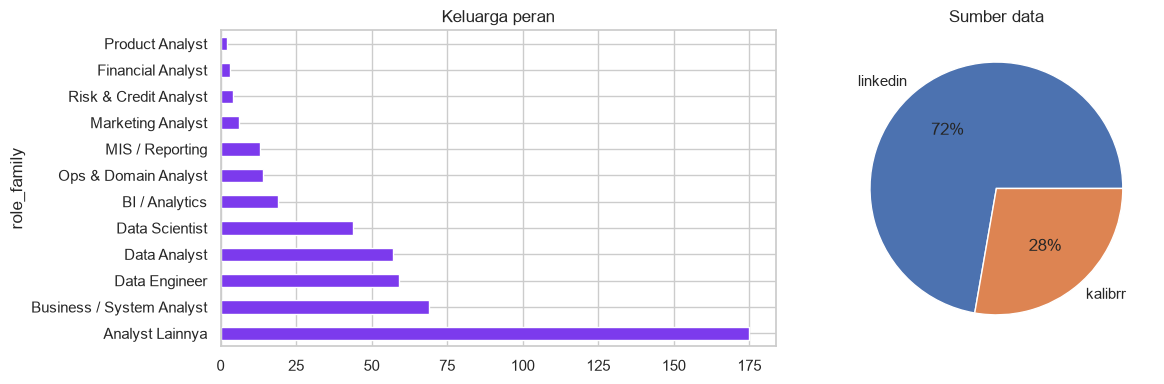

In [2]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
lv.role_family.value_counts().plot.barh(ax=ax[0], color='#7C3AED')
ax[0].set_title('Keluarga peran')
lv.sumber.value_counts().plot.pie(ax=ax[1], autopct='%.0f%%')
ax[1].set_ylabel(''); ax[1].set_title('Sumber data')
plt.tight_layout()

## Skill demand — apa yang benar-benar diminta pasar?

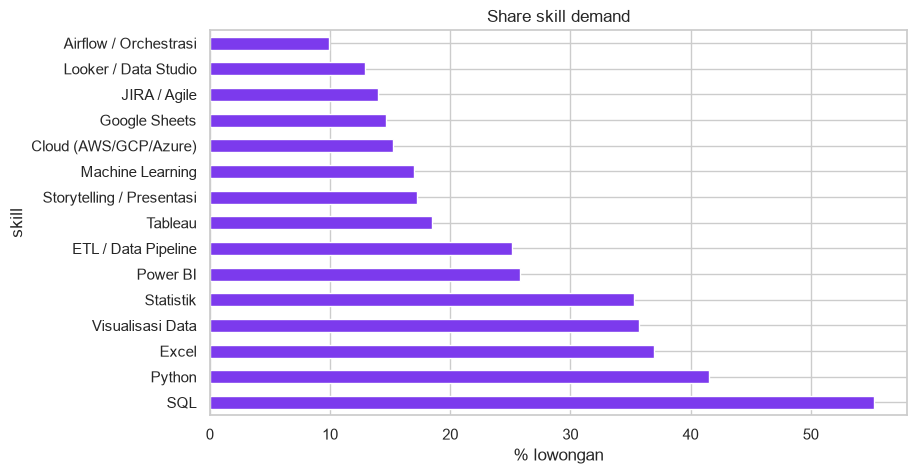

skill
SQL                          257
Python                       193
Excel                        172
Visualisasi Data             166
Statistik                    164
Power BI                     120
ETL / Data Pipeline          117
Tableau                       86
Storytelling / Presentasi     80
Machine Learning              79
Cloud (AWS/GCP/Azure)         71
Google Sheets                 68
JIRA / Agile                  65
Looker / Data Studio          60
Airflow / Orchestrasi         46
Name: count, dtype: int64


In [3]:
n = len(lv)
top = sk.skill.value_counts().head(15)
(top / n * 100).plot.barh(color='#7C3AED', figsize=(9, 5))
plt.xlabel('% lowongan'); plt.title('Share skill demand')
plt.show()
print(top)

## Geografi & cara kerja

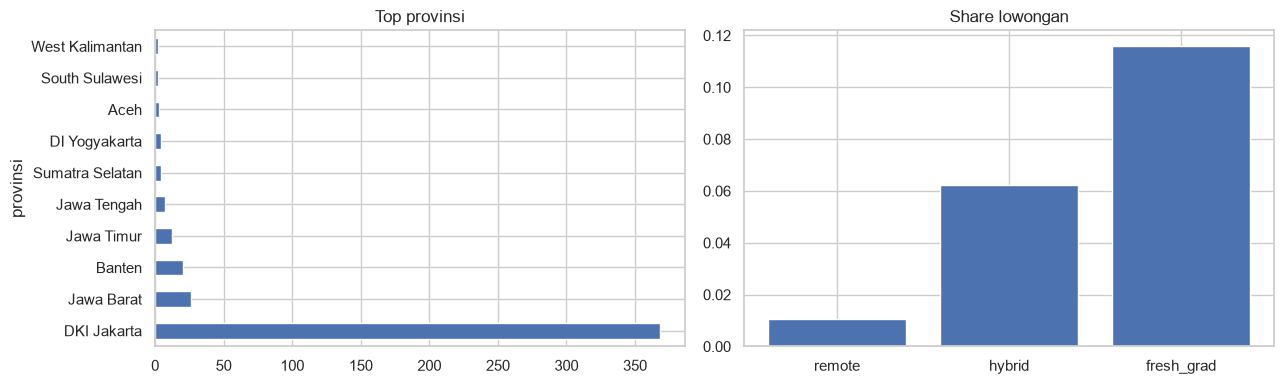

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
lv.provinsi.value_counts().head(10).plot.barh(ax=ax[0])
ax[0].set_title('Top provinsi')
ax[1].bar(['remote', 'hybrid', 'fresh_grad'],
          [lv.remote.mean(), lv.hybrid.mean(), lv.fresh_grad_ok.mean()])
ax[1].set_title('Share lowongan'); plt.tight_layout()

## Gaji — analisis terbatas pada lowongan transparan
Hanya ~6% lowongan menampilkan gaji (Kalibrr saja).

18/465 lowongan bergaji


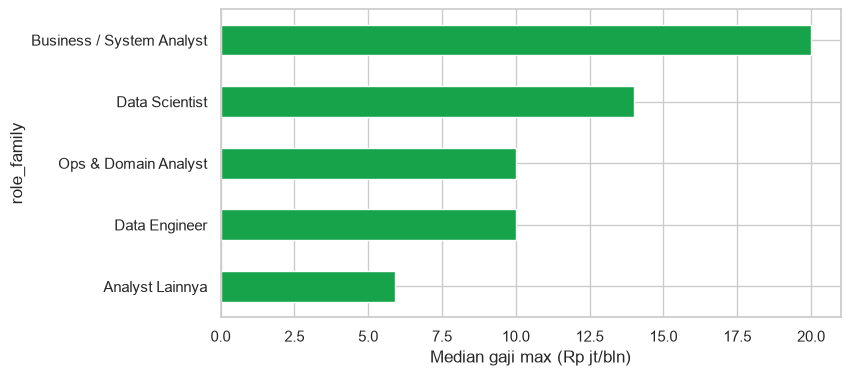

In [5]:
bg = lv.dropna(subset=['gaji_max_jt'])
print(f'{len(bg)}/{len(lv)} lowongan bergaji')
(bg.groupby('role_family').gaji_max_jt.median().sort_values()
   .plot.barh(figsize=(8,4), color='#16A34A'))
plt.xlabel('Median gaji max (Rp jt/bln)'); plt.show()

## Insight utama
1. Pasar analitik RI terkonsentrasi ekstrem di DKI Jakarta.
2. Dua platform, dua pasar: Kalibrr=Excel-first (UKM), LinkedIn=SQL/Python-first (enterprise).
3. Remote murni langka — hybrid mulai muncul tapi minoritas.
4. Transparansi gaji sangat rendah: analisis gaji bias.
5. Search job board noisy: ~22% hasil benar-benar relevan.